In [2]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# API Configuration
API_KEY = os.getenv("OPENWEATHER_API_KEY")
if not API_KEY:
    raise ValueError("Set the OPENWEATHER_API_KEY environment variable before running this cell.")

CITY = "Pune"
COUNTRY = "IN"

URL = "https://api.openweathermap.org/data/2.5/weather"

params = {
    "q": f"{CITY},{COUNTRY}",
    "appid": API_KEY,
    "units": "metric"
}

# Send API request
response = requests.get(URL, params=params)

if response.status_code == 200:
    print("API Connected Successfully!")
    weather_data = response.json()
else:
    print("Error:", response.status_code)
    print(response.text)

API Connected Successfully!


In [7]:
if response.status_code == 200:

    print("City:", weather_data['name'])
    print("Temperature:", weather_data['main']['temp'], "°C")
    print("Humidity:", weather_data['main']['humidity'], "%")
    print("Pressure:", weather_data['main']['pressure'], "hPa")
    print("Wind Speed:", weather_data['wind']['speed'], "m/s")
    print("Weather:", weather_data['weather'][0]['description'])
    print("Cloudiness:", weather_data['clouds']['all'], "%")

City: Pune
Temperature: 25.51 °C
Humidity: 62 %
Pressure: 1014 hPa
Wind Speed: 3.58 m/s
Weather: moderate rain
Cloudiness: 99 %


In [9]:
# Extract weather information
weather = {
    'City': weather_data['name'],
    'Temperature': weather_data['main']['temp'],
    'Feels_Like': weather_data['main']['feels_like'],
    'Humidity': weather_data['main']['humidity'],
    'Pressure': weather_data['main']['pressure'],
    'Wind_Speed': weather_data['wind']['speed'],
    'Weather': weather_data['weather'][0]['description'],
    'Cloudiness': weather_data['clouds']['all']
}

# Convert dictionary into DataFrame
df = pd.DataFrame([weather])

print(df)

   City  Temperature  Feels_Like  Humidity  Pressure  Wind_Speed  \
0  Pune        25.51       25.74        62      1014        3.58   

         Weather  Cloudiness  
0  moderate rain          99  


In [11]:
FORECAST_URL = "https://api.openweathermap.org/data/2.5/forecast"

forecast_params = {
    "q": f"{CITY},{COUNTRY}",
    "appid": API_KEY,
    "units": "metric"
}

forecast_response = requests.get(
    FORECAST_URL,
    params=forecast_params
)

if forecast_response.status_code == 200:
    forecast_data = forecast_response.json()
    print("Forecast data retrieved successfully!")
else:
    print("Error:", forecast_response.text)

Forecast data retrieved successfully!


In [13]:
forecast_list = []

for item in forecast_data['list']:

    forecast_list.append({
        'Date': item['dt_txt'],
        'Temperature': item['main']['temp'],
        'Humidity': item['main']['humidity'],
        'Pressure': item['main']['pressure'],
        'Wind_Speed': item['wind']['speed'],
        'Weather': item['weather'][0]['description'],
        'Cloudiness': item['clouds']['all'],
        'Rain': item.get('rain', {}).get('3h', 0)
    })

forecast_df = pd.DataFrame(forecast_list)

print(forecast_df.head())

                  Date  Temperature  Humidity  Pressure  Wind_Speed  \
0  2026-11-01 15:00:00        27.31        56      1014        1.00   
1  2026-11-01 18:00:00        26.62        69      1014        0.50   
2  2026-11-01 21:00:00        25.15        84      1014        1.39   
3  2026-11-02 00:00:00        25.33        83      1014        2.73   
4  2026-11-02 03:00:00        23.91        87      1017        2.17   

         Weather  Cloudiness  Rain  
0     light rain          82  1.42  
1     light rain          80  0.22  
2     light rain          87  1.37  
3  moderate rain          91  3.82  
4     light rain         100  0.56  


In [15]:
# Check missing values
print("Missing Values:")
print(forecast_df.isnull().sum())

# Remove duplicate records
forecast_df.drop_duplicates(inplace=True)

# Handle missing values
forecast_df.fillna(0, inplace=True)

# Convert Date into datetime format
forecast_df['Date'] = pd.to_datetime(forecast_df['Date'])

# Sort data by date
forecast_df.sort_values('Date', inplace=True)

print("\nCleaned Weather Data:")
print(forecast_df.head())

Missing Values:
Date           0
Temperature    0
Humidity       0
Pressure       0
Wind_Speed     0
Weather        0
Cloudiness     0
Rain           0
dtype: int64

Cleaned Weather Data:
                 Date  Temperature  Humidity  Pressure  Wind_Speed  \
0 2026-11-01 15:00:00        27.31        56      1014        1.00   
1 2026-11-01 18:00:00        26.62        69      1014        0.50   
2 2026-11-01 21:00:00        25.15        84      1014        1.39   
3 2026-11-02 00:00:00        25.33        83      1014        2.73   
4 2026-11-02 03:00:00        23.91        87      1017        2.17   

         Weather  Cloudiness  Rain  
0     light rain          82  1.42  
1     light rain          80  0.22  
2     light rain          87  1.37  
3  moderate rain          91  3.82  
4     light rain         100  0.56  


C:\Users\tanis\AppData\Local\Temp\ipykernel_13284\2717422373.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  forecast_df.drop_duplicates(inplace=True)
C:\Users\tanis\AppData\Local\Temp\ipykernel_13284\2717422373.py:15: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  forecast_df.sort_values('Date', inplace=True)


In [17]:
# Statistical summary
print(forecast_df.describe())

# Calculate average temperature
print("Average Temperature:",
      forecast_df['Temperature'].mean())

# Calculate maximum temperature
print("Maximum Temperature:",
      forecast_df['Temperature'].max())

# Calculate minimum temperature
print("Minimum Temperature:",
      forecast_df['Temperature'].min())

# Calculate average humidity
print("Average Humidity:",
      forecast_df['Humidity'].mean())

# Calculate average wind speed
print("Average Wind Speed:",
      forecast_df['Wind_Speed'].mean())

                      Date  Temperature   Humidity     Pressure  Wind_Speed  \
count                   40    40.000000  40.000000    40.000000   40.000000   
mean   2026-11-04 01:30:00    26.510500  65.000000  1014.425000    1.918250   
min    2026-11-01 15:00:00    22.370000  36.000000  1012.000000    0.100000   
25%    2026-11-02 20:15:00    24.892500  55.750000  1013.000000    1.007500   
50%    2026-11-04 01:30:00    26.385000  66.000000  1014.000000    1.905000   
75%    2026-11-05 06:45:00    28.337500  74.500000  1015.000000    2.677500   
max    2026-11-06 12:00:00    31.770000  87.000000  1017.000000    4.350000   
std                    NaN     2.490381  13.258766     1.375379    1.105531   

       Cloudiness      Rain  
count    40.00000  40.00000  
mean     63.17500   0.51850  
min       9.00000   0.00000  
25%      37.00000   0.00000  
50%      70.50000   0.05000  
75%      91.00000   0.57500  
max     100.00000   3.82000  
std      29.52868   0.97655  
Average Temperatur

In [19]:
# Group weather data by date
forecast_df['Day'] = forecast_df['Date'].dt.date

daily_weather = forecast_df.groupby('Day').agg({
    'Temperature': 'mean',
    'Humidity': 'mean',
    'Wind_Speed': 'mean',
    'Rain': 'sum'
})

print("Daily Weather Analysis:")
print(daily_weather)

Daily Weather Analysis:
            Temperature   Humidity  Wind_Speed   Rain
Day                                                  
2026-11-01     26.36000  69.666667    0.963333   3.01
2026-11-02     26.76250  75.250000    2.053750  13.23
2026-11-03     25.79375  70.875000    1.498750   3.56
2026-11-04     26.37250  61.500000    1.587500   0.94
2026-11-05     26.57250  57.250000    2.278750   0.00
2026-11-06     27.46600  54.400000    2.898000   0.00


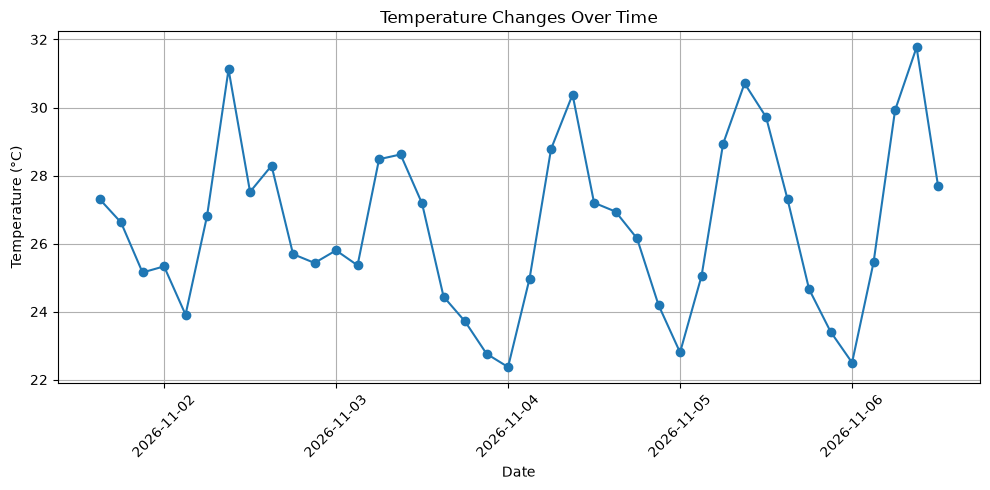

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    forecast_df['Date'],
    forecast_df['Temperature'],
    marker='o'
)

plt.title('Temperature Changes Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

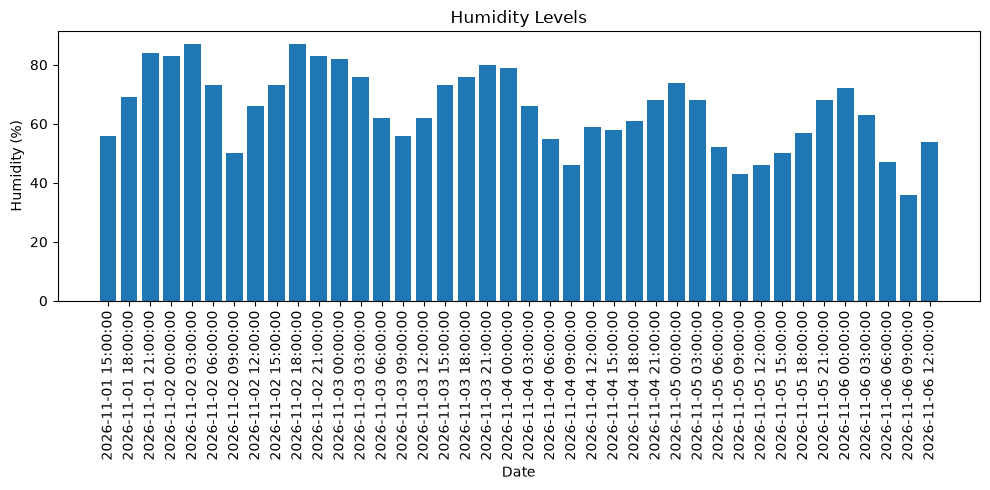

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    forecast_df['Date'].astype(str),
    forecast_df['Humidity']
)

plt.title('Humidity Levels')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

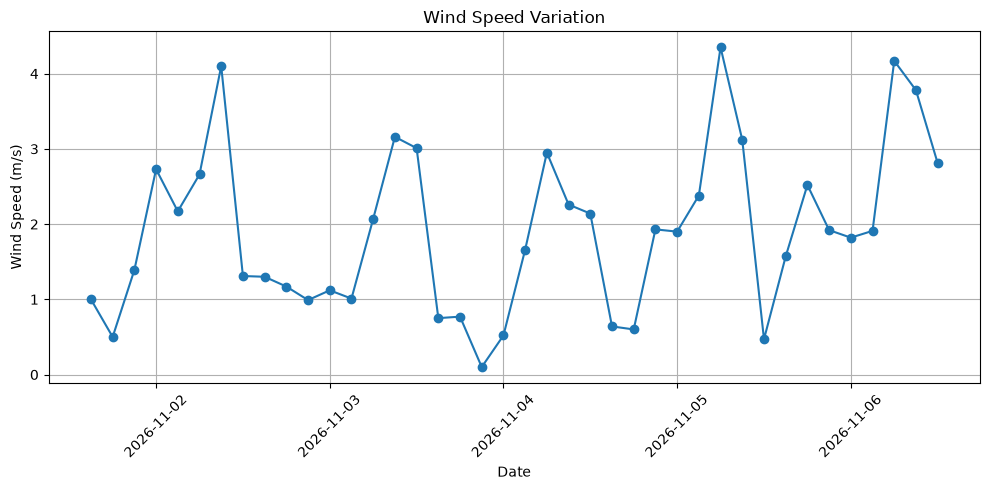

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    forecast_df['Date'],
    forecast_df['Wind_Speed'],
    marker='o'
)

plt.title('Wind Speed Variation')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

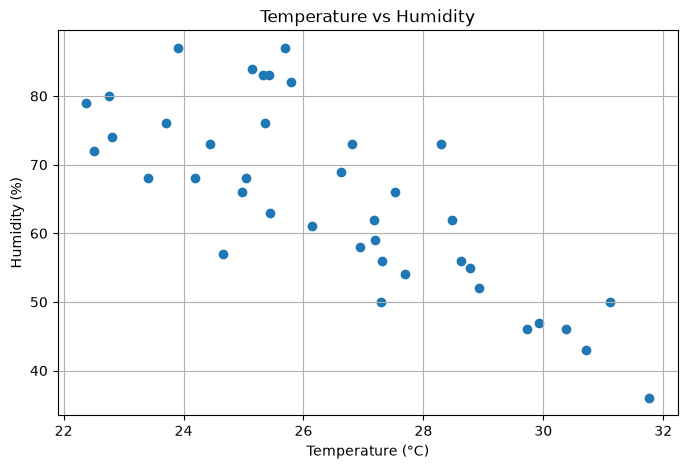

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(
    forecast_df['Temperature'],
    forecast_df['Humidity']
)

plt.title('Temperature vs Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')

plt.grid()
plt.show()

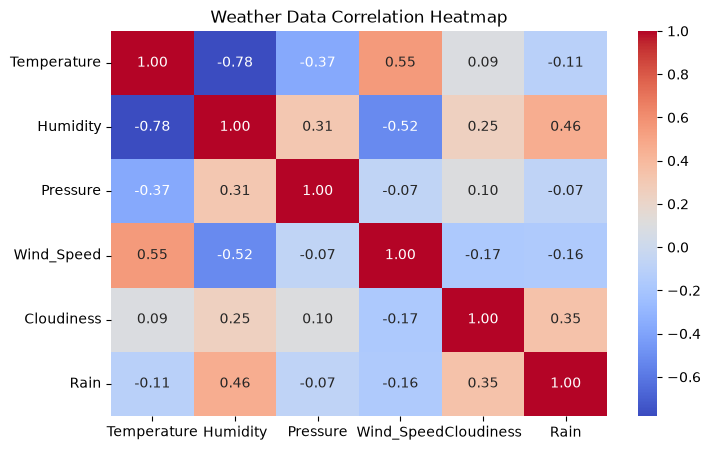

In [26]:
plt.figure(figsize=(8, 5))

correlation = forecast_df[
    ['Temperature', 'Humidity', 'Pressure',
     'Wind_Speed', 'Cloudiness', 'Rain']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Weather Data Correlation Heatmap')
plt.show()

In [27]:
latitude = weather_data['coord']['lat']
longitude = weather_data['coord']['lon']

print("City:", CITY)
print("Latitude:", latitude)
print("Longitude:", longitude)

City: Pune
Latitude: 18.5196
Longitude: 73.8553


In [28]:
# Save weather data into CSV
forecast_df.to_csv('weather_data.csv', index=False)

# Save weather data into Excel
forecast_df.to_excel('weather_data.xlsx', index=False)

print("Weather data saved successfully!")

Weather data saved successfully!
